## 📖 Série d'exercices 2: Numpy et Matplotlib (à faire vous-même)

##### 🤾 Exercice 1: Le retour du lanceur de poids.

<div class="alert alert-block alert-info">
<b>Contexte:</b> 

Un lanceur de poids a une infinité d'angles par rapport à l'horizontale auxquels il peut lancer son poids. Lequel choisir pour lancer le poids le plus loin possible ?
</div>


Dans la dernière série d'exercices, vous avez pu voir comment calculer la portée d'objet lancé à $y_0=0$ avec une vitesse initiale $v_0$ et un angle $\theta$ par rapport à l'horizontale. Je vous montre ici la nouvelle dérivation si le poids est lancé à une hauteur $y_0$.

Pour les composantes du vecteur accélération, on a
$$
\begin{align}
a_x &= 0 \\
a_y &= -g
\end{align}
$$
Pour les composantes du vecteur vitesse, on a
$$
\begin{align}
v_x &= v_0\cos(\theta)
\\
v_y &= -g t+  v_0\sin(\theta)
\end{align}
$$
Finalement, le vecteur position a les composantes suivantes
$$
\begin{align}
x(t) &= v_0\cos(\theta) t
\\
y(t) &= -\frac{1}{2}g t^2 + v_0\sin(\theta) t + y_0
\end{align}
$$

Notez l'ajout de la constante $y_0$ par rapport à l'expression de la dernière fois. La constante est ici une constante d'intégration puisque
$$
\begin{align}
y(t) - y(0) &= \int_{0}^ {t} \frac{dy}{dt}dt \\
&= \int_{0}^{t} -gt +v_0\sin(\theta) dt
\\
&= -\frac{1}{2}gt^2 +v_0\sin(\theta)t 
\end{align}
$$
Par conséquent
$$
y(t) = -\frac{1}{2}gt^2 +v_0\sin(\theta)t + y_0
$$

En solutionnant l'équation du second degré $y(t)=0$, on trouve le temps de vol du poids
$$
T = \frac{v_0\sin(\theta) +\sqrt{v_0^2 \sin^{2}(\theta)+ 2 g y_0}}{g}
$$

Il suffit maintenant de remplacer dans l'expression de $x(t)$ pour obtenir notre nouvelle expression pour la portée $P$
$$
P =\frac{v_0\cos(\theta)}{g} \left[v_0\sin(\theta) + \sqrt{v_0^2 \sin^2(\theta) + 2g y_0}\right]
$$

On voit que l'expression ci-dessus est légèrement différente à notre ancienne expression
$$
P^ {\text{old}} = \frac{v_0^2 \sin(2\theta)}{g}
$$
(notez que pour $v_0^2\sin^2(\theta) >> 2g y_0$, la nouvelle expression est équivalente à l'ancienne).


*Question 1: Créer les fonctions `old_compute_range` et `compute_range`* 

Notre premier objectif est de créer deux fonctions qui vont calculer la portée en fonction de l'angle $\theta$ et avec paramètres par défaut la vitesse initiale `v_init=15` et l'accélération de la pesanteur `g=9.81`. La première fonction `old_compute_range` correspond au calcul où on assume $y_0=0$ tandis que la seconde, `compute_range` correspond au calcul où $y_0\neq 0$.  Vous pouvez utiliser la fonction `np.radians` pour convertir l'angle en degrés en radians.

Afin de tester les fonctions, porter en graphique la portée en fonction de l'angle initiale $\theta$ pour les deux fonctions en utilisant matplotlib pour des valeurs de $\theta$ variant de 10 degrés à 85 degrés. Annotez les axes de la figure de manière appropriée (axe des $x$ correspond à $\theta$, tandis que l'axe des $y$ correspond à la portée $P(\theta)$)

In [2]:
import numpy as np 

def old_compute_range(angle, v_init = 15, g = 9.81):
    angle = np.radians(angle)
    throw_range = v_init ** 2 * np.sin(2 * angle) / g

    return throw_range

def compute_range(angle, v_init = 15, g = 9.81, y_init = 1.5):
    angle = np.radians(angle)

    a = v_init * np.cos(angle) / g
    b = v_init * np.sin(angle) + (v_init ** 2 * np.sin(angle) ** 2 + 2 * g * y_init) ** 0.5
    throw_range = a * b

    return throw_range

[Text(0.5, 0, '$\\theta$'), Text(0, 0.5, '$x(T)$')]

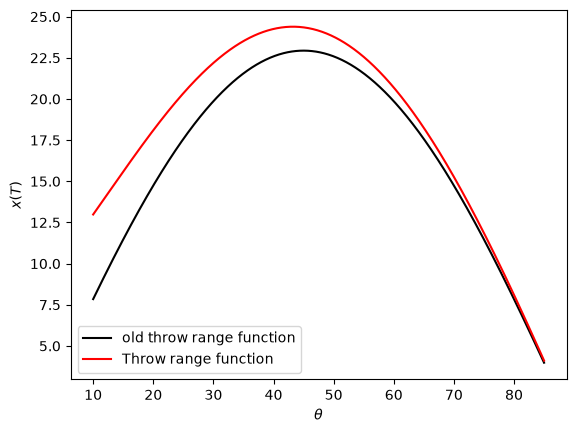

In [3]:
import matplotlib.pyplot as plt
# Plotting the curves in function of angle theta

angles = np.linspace(10, 85, 1000)

old_throw_ranges = old_compute_range(angles)
throw_ranges = compute_range(angles)

plt.plot(angles, old_throw_ranges, color = "k", label = "old throw range function")
plt.plot(angles, throw_ranges, color = "red", label = "Throw range function")
plt.legend()
plt.gca().set(xlabel = r"$\theta$", ylabel = r"$x(T)$")

Si votre implémentation est correcte, vous devriez voir que le maximum de notre nouvelle fonction est différent du maximum de la fonction de la série d'exercices précédente. 

*Question 2: Variation de la portée maximale en fonction de l'accélération de la pesanteur*. 

Afin d'étudier comment la portée maximale varie en fonction de l'accélération de la pesanteur, portez en graphique la portée (de la fonction `compute_range`) en fonction de l'angle $\theta$ pour des valeurs de $g$ variant de 1 à 20 $\text{m/s}^2$ (disons 100 valeurs de $g$). 


Astuce: Vous pouvez utiliser une échelle de couleur pour les différentes accélérations de pesanteur avec le snippet de code ci-dessous (à compléter)

```python
from matplotlib.cm import ScalarMappable

fig, axs = plt.subplots(1, 1, figsize = (6, 4))
cmap = plt.get_cmap("rainbow")
gs = ...
colors = cmap(np.linspace(0, 1, len(gs)))

for color, g in zip(colors, gs):
    axs.plot(..., ..., color = color)

sm = ScalarMappable(cmap = cmap, norm = plt.Normalize(vmin = gs.min(), vmax = gs.max()))
plt.colorbar(sm, ax = axs)
```

[Text(0.5, 0, '$\\theta$'), Text(0, 0.5, '$x(\\theta)$')]

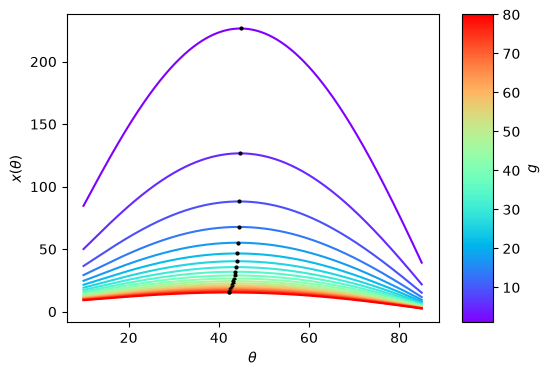

In [25]:
from matplotlib.cm import ScalarMappable

fig, axs = plt.subplots(1, 1, figsize = (6, 4))
cmap = plt.get_cmap("rainbow")

angles = np.linspace(10, 85, 1000)
gs = np.linspace(1, 80, 100)
colors = cmap(np.linspace(0, 1 ,20))

for color, g in zip(colors, gs):
    throw_range = compute_range(angles, g = g)
    idx_max = throw_range.argmax()
    axs.plot(angles, throw_range, color = color, zorder = 1)
    axs.scatter(angles[idx_max], throw_range[idx_max], s = 4, color = "k")

sm = ScalarMappable(cmap = cmap, norm = plt.Normalize(vmin = gs.min(), vmax = gs.max()))
plt.colorbar(sm, ax = axs, aspect = 10, label = r"$g$")

axs.set(xlabel=r"$\theta$", ylabel =r"$x(\theta)$")

*Question 2: Variation de la portée maximale en fonction de la vitesse initiale*. 

Afin d'étudier comment la portée maximale varie en fonction de la vitesse initiale, portez en graphique la portée (de la fonction `compute_range`) en fonction de l'angle $\theta$ pour des valeurs de $v_0$ variant de 10 à 25 $\text{m/s}$ (disons 100 valeurs de $v_0$). 

[Text(0.5, 0, '$\\theta$'), Text(0, 0.5, '$x(\\theta)$')]

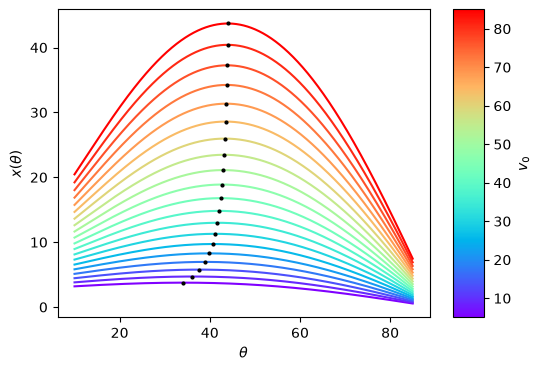

In [27]:
from matplotlib.cm import ScalarMappable

fig, axs = plt.subplots(1, 1, figsize = (6, 4))
cmap = plt.get_cmap("rainbow")

angles = np.linspace(10, 85, 10_000)
v_inits = np.linspace(5, 85, 100)
colors = cmap(np.linspace(0, 1 ,20))

for color, v_init in zip(colors, v_inits):
    throw_range = compute_range(angles, v_init = v_init)
    idx_max = throw_range.argmax()
    axs.plot(angles, throw_range, color = color, zorder = 1)
    axs.scatter(angles[idx_max], throw_range[idx_max], s = 4, color = "k")

sm = ScalarMappable(cmap = cmap, norm = plt.Normalize(vmin = v_inits.min(), vmax = v_inits.max()))
plt.colorbar(sm, ax = axs, aspect = 10, label = r"$v_0$")

axs.set(xlabel=r"$\theta$", ylabel =r"$x(\theta)$")

Que remarquez vous ? Est-ce que l'angle qui maximise la portée semble dépendre de $g$ ou de $v_0$ ?

**Oui, visuellement, l'angle $\theta$ maximisant la portée dépend de $v_0$ et de $g$.**

*Question 3: Méthode numérique d'estimation du maximum*

Réutiliser le même algorithme que la dernière fois pour estimer le maximum de la portée pour $v_0=15 \text{ m/s}$ et $g=9.81\text{ m/s}^2$

In [31]:
# Step 1: Point candidates
x0 = 10
x1 = 85

# Step 2
x_mid = (x0 + x1) / 2

eps_min = 1e1

i = 0


# Step 3 and 4
while eps_min >1e-12:
    f0 = compute_range(x0)
    fmid = compute_range(x_mid)
    f1 = compute_range(x1)

    if f0 < fmid:
        x0_next = x_mid

    elif f1 < fmid:
        x0_next = x_mid 

    if f0 < f1:
        x1_next = x1
    else:
        x1_next = x0
    
    x_mid_next = (x0_next + x1_next) / 2
    eps_min = abs(compute_range(x_mid) - compute_range(x_mid_next)) 

    # Replacing the variables for the next loop of the algorithm and Step 2 again
    x0 = x0_next
    x1 = x1_next
    x_mid = x_mid_next

print(x0, x_mid, x1)

43.240339159965515 43.24033468961716 43.2403302192688


On peut montrer que l'angle maximisant la portée est donnée par l'expression suivante
$$
\theta_{\max} = \arctan\left(\frac{v_0}{\sqrt{v_0^2 + 2g y_0}}\right)
$$

Écrivez une fonction prenant pour paramètre `v_init`, `g` et `y_0` et calculez $\theta_{\max}$ pour $v_0=15\text{ m/s}$, $g=9.81 \text{ m/s}^2$ et $y_0=1.5\text{ m}$.  

Est-ce que la méthode numérique est en accord avec la solution analytique ?

In [30]:
def compute_theta_max(v_init, g, y_0):
    angle = np.arctan(v_init / np.sqrt(v_init ** 2 + 2 * g * y_0)) 
    return np.degrees(angle)

compute_theta_max(v_init = 15, g = 9.81, y_0 = 1.5)

np.float64(43.24033166410235)

Pour terminer, étudiez comment l'angle maximal change en fonction de $g$, $v_0$ et $y_0$. Vous pouvez faire trois figures différentes. À chaque fois, mettez une barre horizontale rouge en pointillés pour indiquer l'angle de 45 degrés obtenu lorsqu'on assume $y_0=0$. 

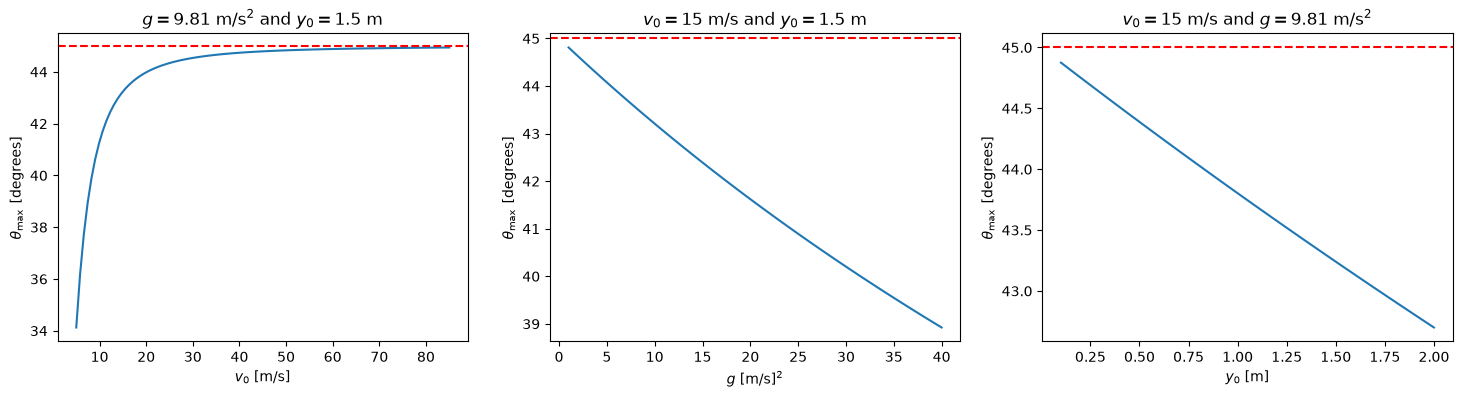

In [53]:
fig, axs = plt.subplots(1, 3, figsize = ( 3 * 6, 4))
cmap = plt.get_cmap("rainbow")

v_inits = np.linspace(5, 85, 100)
angles = compute_theta_max(g=9.81, v_init = v_inits, y_0 = 1.5)

ax = axs[0]
ax.plot(v_inits, angles)
ax.set(xlabel=r"$v_0$ [m/s]", ylabel =r"$\theta_{\max}$ [degrees]", title = r"$g=9.81\text{ m/s}^2$ and $y_0=1.5$ m")
ax.axhline(45, color = "red", ls = "dashed")

gs = np.linspace(1, 40, 100)
angles = compute_theta_max(g=gs, v_init = 15, y_0 = 1.5)

ax = axs[1]
ax.plot(gs, angles)
ax.set(xlabel=r"$g \text{ [m/s]}^2$", ylabel =r"$\theta_{\max}$ [degrees]", title = r"$v_0=15\text{ m/s}$ and $y_0=1.5$ m")
ax.axhline(45, color = "red", ls = "dashed")


y0s = np.linspace(0.1, 2, 100)
angles = compute_theta_max(g=9.81, v_init = 15, y_0 = y0s)

ax = axs[2]
ax.plot(y0s, angles)
ax.set(xlabel=r"$y_0 \text{ [m]}$", ylabel =r"$\theta_{\max}$ [degrees]", title = r"$v_0=15\text{ m/s}$ and $g=9.81 \text{ m/s}^2$")
ax.axhline(45, color = "red", ls = "dashed")

##### Exercice 2: Simulateur de jeu de pierre-feuille-ciseaux

Cet exercice est plutôt libre sur la façon dont vous faîtes l'implémentation mais l'objectif est de faire un jeu de pierre-feuille-ciseaux en python. Votre simulateur devra

1) Demander aux 2 joueurs combien de parties vont être jouées
2) Demander au joueur 1 sa réponse entre `"paper"`, `"scissors"` et `"rock"`.
3) Demander au joueur 2 sa réponse entre `"paper"`, `"scissors"` et `"rock"`.
4) Étant donné la réponse à 2 et 3, afficher le vainqueur de la manche.
5) Répéter 2, 3 et 4 jusqu'à ce qu'on atteigne le nombre de parties spécifié en 1). Déterminer finalement le grand vainqueur en comparant le nombre de manches gagné.

In [17]:

num_games = int(input("How many games would you like to play ?"))

wins_player_1 = 0
wins_player_2 = 0
for i in range(num_games):
    print(f"Game {i+1}/{num_games}") 
    print(f"Current score {wins_player_1}-{wins_player_2}")
    print(40 * "-")

    player_1 = input("Player 1, choose between 'rock', 'paper' and 'scissors'")
    player_2 = input("Player 2, choose between 'rock', 'paper' and 'scissors'")
    possible_answers = ['rock', 'paper', 'scissors']

    if (player_1 not in possible_answers) or (player_2 not in possible_answers):
        print("You entered a word that is not valid. Choose between 'rock', 'paper' and 'scissors'")
        break

    if (player_1 == "rock") and (player_2 == "scissors"):
        print("Player 1 wins this game !")
        wins_player_1 +=1
        continue
    
    elif (player_1 == "paper") and (player_2 == "rock"):
        print("Player 1 wins this game!")
        wins_player_1 +=1
        continue

    elif (player_1 == "scissors") and (player_2 == "paper"):
        print("Player 1 wins this game!")
        wins_player_1 +=1
        continue

    elif player_1 == player_2:
        print("That's a draw.")
        continue 

    else:
        print("Player 2 wins this game!")
        wins_player_2 += 1

if wins_player_1 > wins_player_2:
    winner = "Player 1"
elif wins_player_1 < wins_player_2:
    winner = "Player 2"
else:
    winner = "Nobody"
print(f"Final score: {wins_player_1}-{wins_player_2}. {winner} wins !")


Game 1/2
Current score 0-0
----------------------------------------
Player 2 wins this game!
Game 2/2
Current score 0-1
----------------------------------------
Player 2 wins this game!
Final score: 0-2. Player 2 wins !


##### Exercice 3: Le pendule simple.

Dans cet exercice, on va étudier un système physique, le pendule simple. 

À partir des lois de Newton, on peut montrer que l'angle que fait le pendule par rapport à la verticale est donné par la formule suivante,
$$
\frac{d^2\theta}{dt^2} = - \frac{g}{L}\sin(\theta)
$$
Ce type d'équation est connu sous le nom d'équation différentielle d'ordre 2. En passant, vous avez déjà rencontré ce type d'équations puisque la seconde loi de Newton n'est rien d'autre qu'une équation différentielle d'ordre 2 également.

Dans cette exercice, nous allons étudier comment résoudre numériquement ce genre d'équation puis comparerons à la solution analytique utilisant une approximation.

La solution analytique que vous verrez dans vos études supérieures s'obtient en utilisant l'approximation des petits angles, ce qui revient à assumer que 
$$
\sin (\theta) \simeq \theta
$$
Ceci est vrai lorsque $\theta$ est assez petit. 

On pose ensuite l'ansatz suivante
$$
\theta(t) = A\cos(\omega t) + B\sin(\omega t)
$$

En dérivant une première fois par rapport au temps, on a
$$
\frac{d \theta}{dt} = -\omega A\sin(\omega t) + B\omega \cos(\omega t)
$$

En dérivant une seconde fois par rapport au temps, on obtient
$$
\begin{align}
\frac{d^2 \theta}{dt^2} &= -\omega^2 A\cos(\omega t) - B\omega^2\sin(\omega t)\\
&= -\omega^2 \theta(t)
\end{align}
$$
En posant $\omega=\sqrt{\frac{g}{L}}$, on voit que notre ansatz est bien une solution de l'équation différentielle. 

Il nous faut maintenant spécifier les conditions initiales avec $\theta(0)=\theta_0$ et $\dot{\theta}(0)=\dot{\theta}_0$

On utilise maintenant les conditions initiales pour obtenir une expression pour $A$ et pour $B$,
$$
\theta(0) = A = \theta_0 \Longrightarrow A = \theta_0
$$

$$
\dot{\theta}(0) = B \omega  = \dot{\theta}_0 \Longrightarrow B = \frac{\dot{\theta}_0}{\omega}
$$

On obtient donc 
$$
\theta(t) = \theta_0 \cos(\omega t) + \frac{\dot{\theta}_0}{\omega}\sin(\omega t)
$$

*Question 1: Visualisation*

Pour commencer, en utilisant `numpy` et `matplotlib` faites une figure montrant le profil de $\theta$ en fonction du temps $t$ pour les paramètres que je vous donne:
- $g=9.81 \ \text{m/s}^2$
- $L=0.5$ m
- $\theta_0 = \pi/4$
- $\dot{\theta}_0 = 0$

[Text(0.5, 0, '$t$'), Text(0, 0.5, '$\\theta(t)$')]

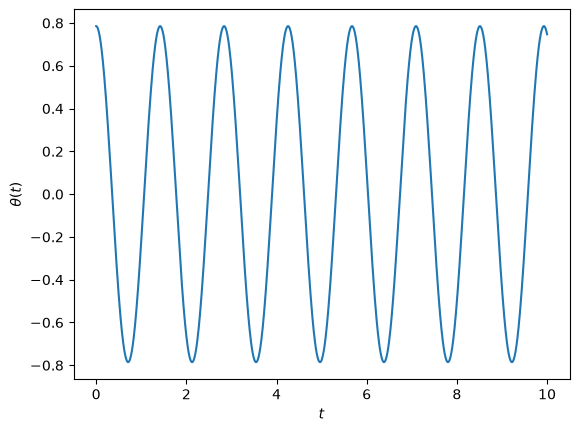

In [56]:
import numpy as np
g = 9.81
L = 0.5
omega = np.sqrt(g / L)
theta_0= np.pi / 4

def pendulum_angle(t, theta_0 = np.pi / 4, g = 9.81, L= 0.5):
    omega = np.sqrt(g / L)
    return theta_0 * np.cos(omega * t)

t = np.linspace(0, 10, 1000)

plt.plot(t, pendulum_angle(t))
plt.gca().set(xlabel = r"$t$", ylabel = r"$\theta(t)$")

*Question 2: Solution numérique du pendule simple avec la méthode d'Euler*
On souhaite maintenant solutionner numériquement le pendule simple sans avoir recours à l'approximation des petits angles. Notez qu'une solution analytique existe mais elle implique une série qui somme une infinité de termes. 

Pour la solution numérique, on va utiliser la *méthode d'Euler* pour résoudre l'équation différentielle.La méthode Euler est applicable pour les équations différentielles de premier ordre. Or celle qu'on a ici est du second ordre. On peut néanmoins utiliser une astuce pour résoudre numériquement. Il est valide ici d'introduire une variable $p$ qui va transformer notre équation différentielle d'ordre 2 en deux équations différentielles de premier ordre.
$$
\begin{align}
\frac{d \theta}{dt} &= p
\\
\frac{dp }{dt} &= -\frac{g}{L}\sin(\theta)
\end{align}
$$

La méthode d'Euler consiste ensuite à réécrire les équations comme suit
$$
\begin{align}
\theta(t + \Delta t)  &= \theta(t) + p \Delta t
\\
p(t + \Delta t) &= p(t) -\frac{g}{L}\sin(\theta(t))\Delta t
\end{align}
$$

En termes de programmation, il faut suivre les étapes suivantes:
- Choisir $\Delta t$. Plus $\Delta t$ est petit, meilleur sera notre résolution numérique. 
- Utilisez `np.arange` pour créer un tableau correspondant au temps `ts` en spécifiant `delta_t` comme le pas.
- Initialiser les premières valeurs des tableaux `theta` et `p` pour respecter les conditions initiales du problème. Dans notre cas, on a 
$$
(\theta_0, p_0) = (\frac{\pi}{4}, 0)
$$
- Itérez avec une boucle `for` sur les indices de tous les éléments du tableau `ts`. Remplissez les tableaux `theta` et `p` selon la règle suivante
$$
\begin{align}
\theta_{i+1} &= \theta_i + p_i \Delta t
\\
p_{i+1} &= p_i -\frac{g}{L}\sin(\theta_i)\Delta t
\end{align}
$$

In [70]:
from tqdm import tqdm 
delta_t = 1e-4
ts = np.arange(0, 10, delta_t)
theta = np.zeros_like(ts)
p = np.zeros_like(ts)

theta[0] = theta_0

for i in tqdm(range(len(ts)-1)):
    theta[i + 1] = theta[i] + p[i] * delta_t
    p[i + 1] = p[i] - omega ** 2 * np.sin(theta[i]) * delta_t

100%|██████████| 99999/99999 [00:00<00:00, 459813.46it/s]


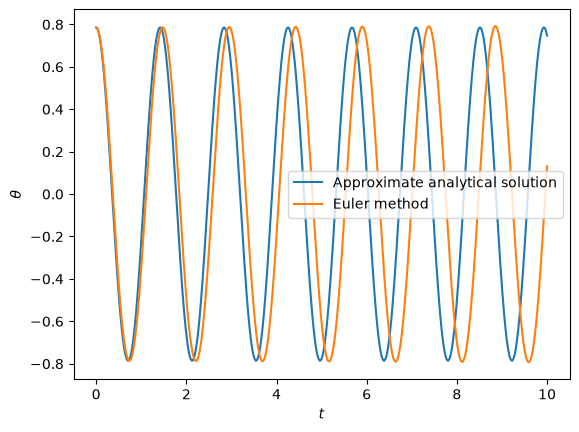

In [82]:
plt.plot(ts, pendulum_angle(ts), label = "Approximate analytical solution")
plt.plot(ts, theta, label = "Euler method")
plt.gca().set(xlabel = r"$t$", ylabel = r"$\theta$")
plt.legend()

Il existe des librairies python qui implémentent ces techniques de résolution d'équation différentielles (et d'autres techniques plus avancées). Par exemple, la fonction `solve_ivp` de la librairie `scipy` permet de solutionner le pendule exactement avec la méthode de Runge-Kutta, une méthode d'intégration qui est plus avancée que la méthode d'Euler. 

In [ ]:
from scipy.integrate import solve_ivp

def pendulum(t, X, g, L):
    """
    Pendulum equations
    """
    theta, p = X
    theta_p = p
    p_p = -g / L * np.sin(theta)
    return theta_p, p_p

# Initial conditions
theta_0, p_0 = np.pi/4, 0

# Pendulum parameters
g = 9.81
L = 0.5
tmax = 10

# Solving with solve_ivp
soln = solve_ivp(pendulum, (0, tmax), (theta_0, p_0), args = (g, L), dense_output = True)

# Interpolate solution onto the time grid.
theta_scipy, p = soln.sol(ts) 

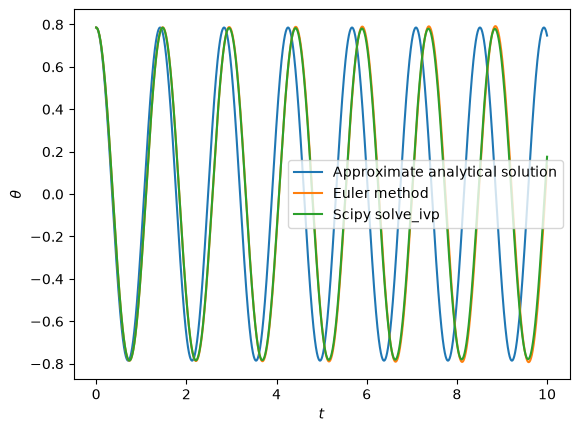

In [83]:
plt.plot(ts, pendulum_angle(ts), label = "Approximate analytical solution")
plt.plot(ts, theta, label = "Euler method")
plt.plot(ts, theta_scipy, label = "Scipy solve_ivp")
plt.gca().set(xlabel = r"$t$", ylabel = r"$\theta$")
plt.legend()

On note que la période du pendule simple n'est pas constante si l'approximation des petits angles ne tient plus ! Vous pouvez tester ça chez vous si vous avez un pendule à la maison.

##### Exercice 4: Visualisation 

Lors du précédent tutoriel, nous avons pu voir comment on peut visualiser des images et des courbes. Nous allons à présent voir comment visualiser des matrices, des nuages de points,  des champs vectoriel et des surfaces en 3D. 

On va commencer par construire une matrice de Toeplitz. Utilisez la [documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.toeplitz.html) de scipy et la documentation sur la fonction `plt.matshow` pour montrer une image d'une matrice de Toeplitz.

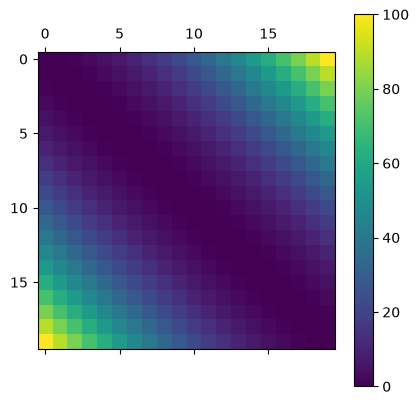

In [88]:
from scipy.linalg import toeplitz

c = (np.linspace(0, 10, 20)) ** 2
matrix = toeplitz(c)

plt.matshow(matrix)
plt.colorbar()

Maintenant, nous allons voir comment visualiser un nuage de points. En bonus, je vous montre aussi comment faire une figure dans l'espace polaire.
(cet exemple est tiré de la [documentation de matplotlib](https://matplotlib.org/stable/gallery/pie_and_polar_charts/polar_scatter.html))

On va commencer par dessiner un escargot une coquille d'escargot dans l'espace polaire. Ceci peut être fait en tracant la courbe suivante 
$$
r(\theta) = \theta 
$$
pour $\theta$ variant de 0 à $2\pi N$ où $N$ est le nombre de boucles que l'on veut pour notre coquille d'escargot. 

La figure peut être faite en coordonnées polaires en spécifiant un argument `subplot_kw = {"projection": "polar"}` comme suit 
```python
fig, axs = plt.subplots(1, 1, figsize = (6, 6), subplot_kw = {"projection": "polar"})
```

Créez d'abord 

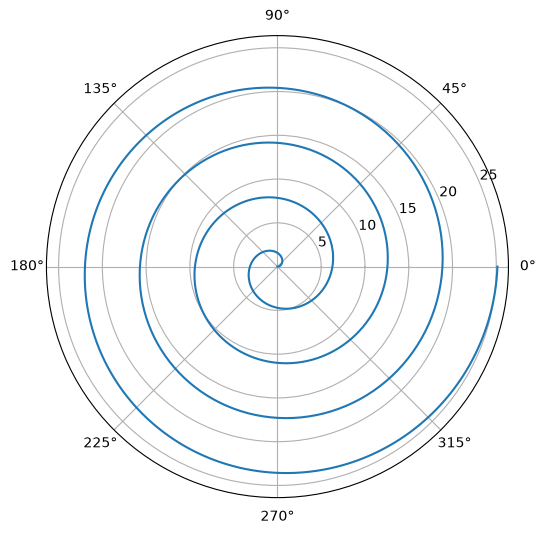

In [ ]:


fig, axs = plt.subplots(1, 1, figsize = (6, 6), subplot_kw={"projection": "polar"})
theta = np.linspace(0, 8 * np.pi, 1000)
r = theta

axs.plot(theta, r)

On va maintenant ajouter de la couleur sur notre coquille d'escargots avec des petits cercles colorées dont la taille et l'emplacement est aléatoire.

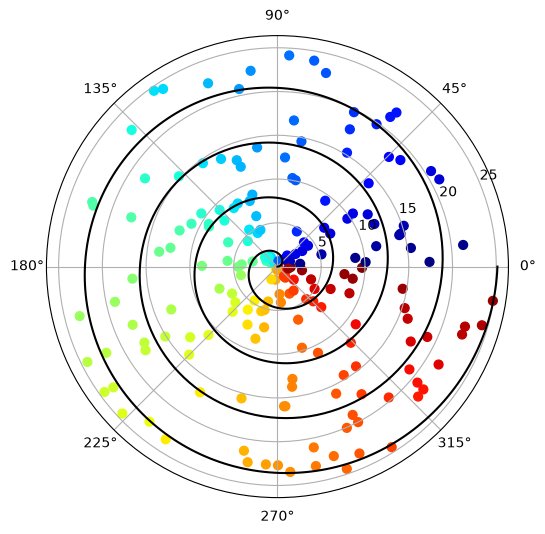

In [123]:

fig, axs = plt.subplots(1, 1, figsize = (6, 6), subplot_kw={"projection": "polar"})
theta = np.linspace(0, 8 * np.pi, 1000)
r = theta
axs.plot(theta, r, color = "k")

N = 200
r_circles = 25 * np.random.rand(N)
theta_circles = 2 * np.pi * np.random.rand(N)
area_circles = 40
# size_circles = 

axs.scatter(x = theta_circles, y = r_circles, s = area_circles, c = theta_circles, cmap = "jet")

Finalement, pour terminer cette série d'exercices déjà un peu longue, on va voir comment faire une figure d'une surface en 3D.
On va essayer de faire le ruban de Möbius défini par les équations suivantes 
$$
\begin{align}
x &= (1 + \frac{t}{2}\cos(\frac{v}{2}))\cos(v)\\
y &= (1 + \frac{t}{2}\cos(\frac{v}{2}))\sin(v)\\
z &=  \frac{t}{2} \sin(\frac{v}{2})
\end{align}
$$
pour $-1\leq t \leq 1$ et pour $0<v\leq 2 \pi$.

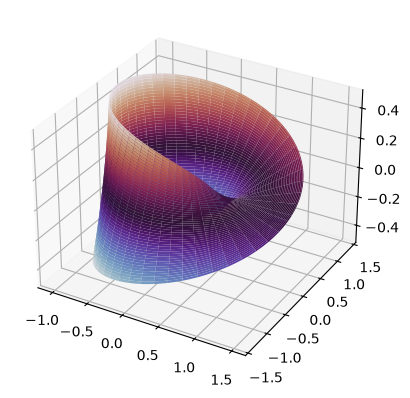

In [126]:
t = np.linspace(-1, 1, 100)
v = np.linspace(0, 2 * np.pi, 100)
T, V = np.meshgrid(t, v)

X = (1 + T / 2 * np.cos(V / 2)) * np.cos(V)
Y = (1 + T / 2 * np.cos(V / 2)) * np.sin(V)
Z = T / 2 * np.sin(V / 2)

fig, axs = plt.subplots(1, 1, subplot_kw = {"projection": "3d"})

axs.plot_surface(X, Y, Z, cmap = "twilight")

Bravo d'être arrivé(e) à la fin de cette série d'exercices 🎓 ! 

Ne vous en faîtes pas s'il y a certains exercices que vous n'avez pas fait, cette série est intentionnellement longue pour y revenir et vous faire pratiquer quand vous en aurez l'envie :). 